# Step 29: Final models (24 conversations, one pipeline, fixed seeds)
Seven models on the same speaker-independent folds and leave-one-language-out runs as step 28. Neural models use 5 seeds (mean +- std over seeds); classic models are deterministic (1 run). Includes the paired statistics between the models (E3) and the causal-smoothing audit (E4).
*This notebook only loads the saved results of `src/29_final_models.py`, `src/30_causal_smoothing.py` and `tools/paired_stats.py`.*

**In short** (what this notebook shows)

- **What:** The 7 final models under one protocol (speaker-independent folds, 5 seeds for neural networks), per-session results, paired statistics and the smoothing audit.
- **Needs the NoXi data?** No: it only loads reports/*.csv, runs in seconds.
- **Result / use:** Dense head on w2v-BERT + VideoMAE with context 0.767 +- 0.017 (0.733 on a new language), significantly better than all other models. Show this to ma'am.

### Dataset
**NoXi** (NOvice eXpert Interaction) - expert-novice conversations with continuous engagement labels.
- Paper: A. Cafaro et al., ACM ICMI 2017 (https://doi.org/10.1145/3136755.3136780); challenge page: https://multimediate.perceptualui.org
- Used here: **24 conversations** (8 English, 8 French, 8 German; 48 people; 48,486 one-second windows) with eGeMAPS voice, OpenFace 2.0 face features and the pretrained w2v-BERT 2.0 / VideoMAE embeddings shipped with the corpus.
- Licence: NoXi is available for research under an End-User Licence Agreement. The data is **not included** and must not be shared.

Go to the project folder.

In [2]:
import os
if os.getcwd().endswith("notebooks"):
    os.chdir("..")          # work from the project folder

**Imports.**

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.width', 220)

**Final models.** CV CCC = pooled CCC per fold, averaged over the 6 folds, then over seeds. Frame-level CCC gives each frame its second's prediction and compares it with the per-frame label (as in the MultiMediate challenge).

In [4]:
f = pd.read_csv('reports/final_models.csv').sort_values('cv_ccc', ascending=False).reset_index(drop=True)
cols = ['model', 'seeds', 'cv_ccc', 'cv_std_over_seeds', 'cv_std_over_folds', 'frame_level_cv_ccc', 'lolo_ccc', 'lolo_English', 'lolo_French', 'lolo_German']
print(f[cols].round(3).to_string(index=False))

                                        model  seeds  cv_ccc  cv_std_over_seeds  cv_std_over_folds  frame_level_cv_ccc  lolo_ccc  lolo_English  lolo_French  lolo_German
dense head: w2v-BERT 2.0 + VideoMAE + context      5   0.767              0.017              0.114               0.761     0.733         0.655        0.807        0.737
          dense head: w2v-BERT 2.0 + VideoMAE      5   0.676              0.011              0.143               0.670     0.627         0.593        0.727        0.559
       Transformer trained from scratch, 10 s      5   0.654              0.015              0.100               0.649     0.600         0.491        0.681        0.627
                                Random Forest      1   0.628              0.000              0.086               0.623     0.546         0.549        0.578        0.510
                                      XGBoost      1   0.625              0.000              0.108               0.619     0.599         0.492        0.673

**Chart:** CV CCC (bars, spread over seeds) and train 2 languages -> 3rd (diamonds).

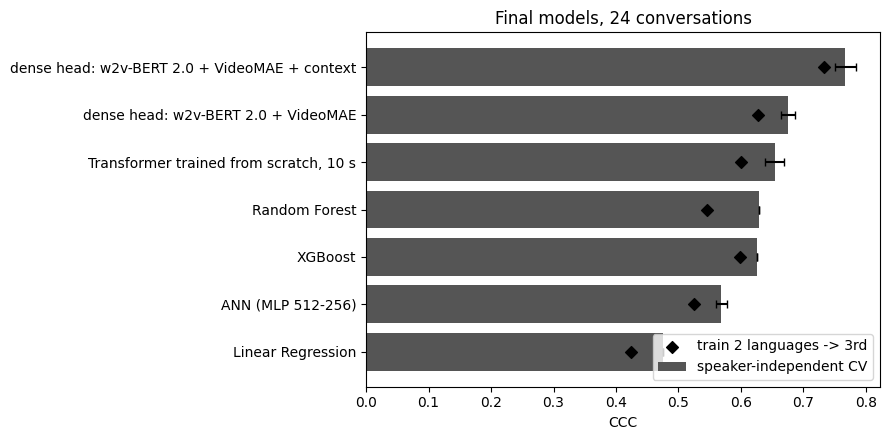

In [5]:
g = f.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(g['model'].str.slice(0, 48), g['cv_ccc'], xerr=g['cv_std_over_seeds'], color='#555555', capsize=3, label='speaker-independent CV')
ax.scatter(g['lolo_ccc'], g['model'].str.slice(0, 48), color='black', marker='D', zorder=3, label='train 2 languages -> 3rd')
ax.set_xlabel('CCC'); ax.legend(loc='lower right'); ax.set_title('Final models, 24 conversations'); plt.tight_layout(); plt.show()

**Per session:** CCC of every session for the best model (shows the spread between conversations).

In [6]:
p = pd.read_csv('reports/final_per_session.csv', dtype={'session': str})
best = f.loc[0, 'model']
s = p[p['model'] == best].sort_values('ccc')
print(best)
print('lowest 3 sessions :', dict(zip(s['session'].head(3), s['ccc'].head(3).round(3))))
print('highest 3 sessions:', dict(zip(s['session'].tail(3), s['ccc'].tail(3).round(3))))

dense head: w2v-BERT 2.0 + VideoMAE + context
lowest 3 sessions : {'030': 0.44, '027': 0.464, '029': 0.512}
highest 3 sessions: {'068': 0.892, '007': 0.906, '072': 0.916}


**Paired statistics (E3).** Per-session CCC of the 24 sessions; mean difference (A - B), session-level bootstrap 95% CI, Wilcoxon test, Holm correction over all 21 pairs.

In [7]:
t = pd.read_csv('reports/final_paired_statistics.csv')
t['model_a'] = t['model_a'].str.slice(0, 30); t['model_b'] = t['model_b'].str.slice(0, 30)
print(t.round(4).to_string(index=False))

                       model_a                        model_b  mean_diff  ci_low  ci_high a_better_sessions  p_wilcoxon  p_holm  significant_0.05
dense head: w2v-BERT 2.0 + Vid dense head: w2v-BERT 2.0 + Vid     0.0749  0.0462   0.1020             21/24      0.0001  0.0013              True
dense head: w2v-BERT 2.0 + Vid Transformer trained from scrat     0.0931  0.0531   0.1280             22/24      0.0001  0.0013              True
dense head: w2v-BERT 2.0 + Vid                  Random Forest     0.1203  0.0601   0.1836             20/24      0.0010  0.0125              True
dense head: w2v-BERT 2.0 + Vid                        XGBoost     0.1176  0.0667   0.1665             20/24      0.0003  0.0045              True
dense head: w2v-BERT 2.0 + Vid              ANN (MLP 512-256)     0.1746  0.1128   0.2343             22/24      0.0000  0.0007              True
dense head: w2v-BERT 2.0 + Vid              Linear Regression     0.2356  0.1677   0.3109             22/24      0.0000  0.0

**Causal smoothing audit (E4).** Smoothing uses only the previous k seconds' predictions (causal). The centered version also uses future predictions and is only a reference. No labels are used.

In [8]:
sm = pd.read_csv('reports/smoothing_causal.csv')
print(sm[['model', 'smoothing', 'uses_future', 'cv_ccc', 'gain_vs_raw', 'gain_std_over_seeds', 'seeds_with_gain']].round(3).to_string(index=False))

                              model                                  smoothing  uses_future  cv_ccc  gain_vs_raw  gain_std_over_seeds  seeds_with_gain
dense head: w2v-BERT 2.0 + VideoMAE                                        raw        False   0.676        0.000                0.000                0
dense head: w2v-BERT 2.0 + VideoMAE                                 causal k=3        False   0.696        0.021                0.001                5
dense head: w2v-BERT 2.0 + VideoMAE                                 causal k=5        False   0.689        0.014                0.002                5
dense head: w2v-BERT 2.0 + VideoMAE                                causal k=10        False   0.655       -0.021                0.002                0
dense head: w2v-BERT 2.0 + VideoMAE centered k=5 (uses future, reference only)         True   0.687        0.012                0.001                5
